## Oppgave 3b)

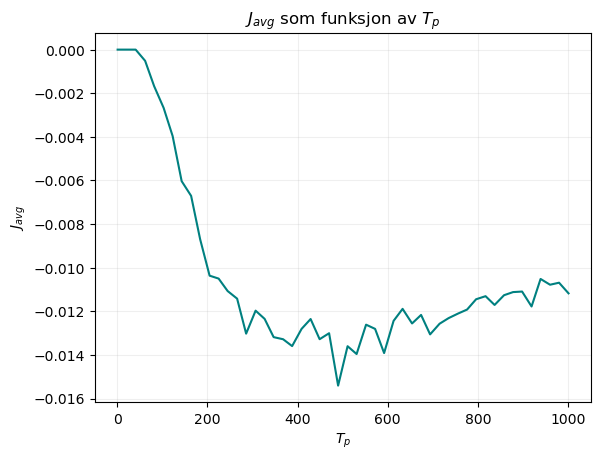

In [ ]:


alpha = 0.8         # bestemmer plassering av topp for sagtannpotensial
N_x = 100
P = 2 * N_x     
N_p = 40 * N_x      # antall partikler
Beta_k = 1000

T_p_vals = np.linspace(1, 1001, 50).astype(int)

np.random.seed(0)   # seed for reproduserbarhet

def build_V1(alpha, N_x):
    peak = int(alpha * N_x)
    n = np.arange(N_x)

    V = np.zeros(N_x, dtype=float)

    left = (n <= peak)
    right = (n > peak)

    V[left]  = n[left] / max(peak, 1)
    V[right] = (N_x - n[right]) / max((N_x - peak), 1)

    return np.concatenate([V, V])

V1 = build_V1(alpha, N_x)
V2 = np.zeros(P)     # Lager et flatt V2

#Finner indeks til minimum til første og andre sagtann
min1 = np.argmin(V1[:N_x])
min2 = N_x + np.argmin(V1[N_x:])

# Lagrer halvparten av partiklene i min til V1 og V2
x0 = np.array([min1] * (N_p // 2) + [min2] * (N_p // 2), dtype=int)

J_avg =  np.zeros(len(T_p_vals))

for i, T_p in enumerate(T_p_vals):

    x = x0.copy()

    J_sum = 0
    n_steps = 2 * T_p

    for j in range(n_steps):
        
        if (j < T_p):
            V = V2
        else:
            V = V1
            
        V_l = V[(x - 1) % P]
        V_0 = V[x]
        V_r = V[(x + 1) % P]

        p_plus  = 1 / (1 + np.exp(-Beta_k*(V_l - V_r)) + np.exp(-Beta_k*(V_0 - V_r)))
        p_minus = 1 / (1 + np.exp(-Beta_k*(V_r - V_l)) + np.exp(-Beta_k*(V_0 - V_l)))
    

        r = np.random.rand(N_p)  # N_p tilfeldige tall mellom 0 og 1
    
        pos = np.zeros_like(x) # tomt array med posisjon 0
        pos[r < p_minus] = -1
        pos[r > 1 - p_plus] = +1

        n_plus  = np.sum(pos == 1)  # teller hvor mange partikler som gikk til høyre
        n_minus = np.sum(pos == -1) # teller hvor mange partikler som gikk til venstre
        J_t = (n_plus - n_minus) / N_p  # current J[i]

        J_sum += J_t
        x = (x + pos) % P  # periodisk randbetingelse
        

    J_avg[i] = J_sum / (2 * T_p)   
    
plt.plot(T_p_vals, J_avg, color = "teal")
plt.title("$J_{avg}$ som funksjon av $T_p$")
plt.grid(alpha = 0.2)
plt.xlabel("$T_p$")
plt.ylabel("$J_{avg}$")
plt.show()

##### Kommentar til kode:

Plottet ovenfor viser gjennomsnittlig strøm, $J_{avg}(n) = \frac{1}{2 T_p} \sum_{1 + 2 T_p n}^{2 T_p(n+1)} J(t_i)$, som funksjon av perioden $T_p$. X-aksen viser verdier for $T_p$ i intervallet (1, 1001), mens y-aksen vsier gjennomsnittlig strøm per syklus $J_{avg}$. For denne oppgaven er $\alpha$ = 0.8, noe som vil si at toppen til sagtannen er forskjøvet mot høyre. For små verdier av perioden $T_p$, er $J_{avg} \approx 0$. Potensialet endres så raskt at partiklene ikke rekker å spre seg eller påvirkes av det asymmetriske sagtannpotensialet. Dermed forsvinner netto strøm og partiklene vil forbli symmetrisk fordelt. Med en økende $T_p$ rekker partiklene å spre seg mer i det flate potensialet $V_2$. Flere partikler vil dermed bevege seg mot venstre når sagtannen blir "slått på" i potensialet $V_1$, og absoluttverdien av strømmen vil øke. Den negative verdien tilsier at partiklene i snitt beveger seg mot venstre, dette står i tråd med resultatene fra oppgave 3a med samme verdi $\alpha$ = 0.8. Strømmen er aller størst ved $T_p \approx 500$. Etter denne verdien observers en økning for $J_{avg}$. Dette kan indikere at asymmetrien utnyttes best for $T_p \approx 500$. Ved større verider avtar absoluttverdien av strømmningen. Dette kan forkalres av at partiklene får for lang tid i hvert potensial. I sagtann-potensialet vil flere av partiklene ende opp i minimumet, altså i bunnen av potensialet. En mulig konsekvens er at bevegelsen dermed blir mer symmetrisk i det flate potensialet. 